In [1]:
import copy, glob, math, os, random, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch import nn

In [2]:
COUNTRY  = "Ireland"
alpha    = 0.98
DATA_DIR = "."
TAG      = "GL"
plt.rcParams['pdf.fonttype'] = 42

TRAIN_FRAC     = 0.8
N_EFF_OVERRIDE = None

SEEDS = [0, 1, 2, 3, 4]

SIGMA_DAYS = (1.0, 14.0)
GAMMA_DAYS = (3.0, 30.0)

SCENARIOS = {"fixsigma": 5.2}

ARCH            = [1, 50, 50, 50, 50, 4]
EPOCHS          = 2000
LBFGS_MAX_STEPS = 300
LBFGS_RTOL      = 1e-9
W_ODE, W_DATA, W_INIT, W_MASS = 30.0, 5.0, 50.0, 10.0

Ireland: days 70-176 (107 days), 2020-03-14 -> 2020-06-28, N_eff = 25,371
train: days 0-84, test: days 85-106


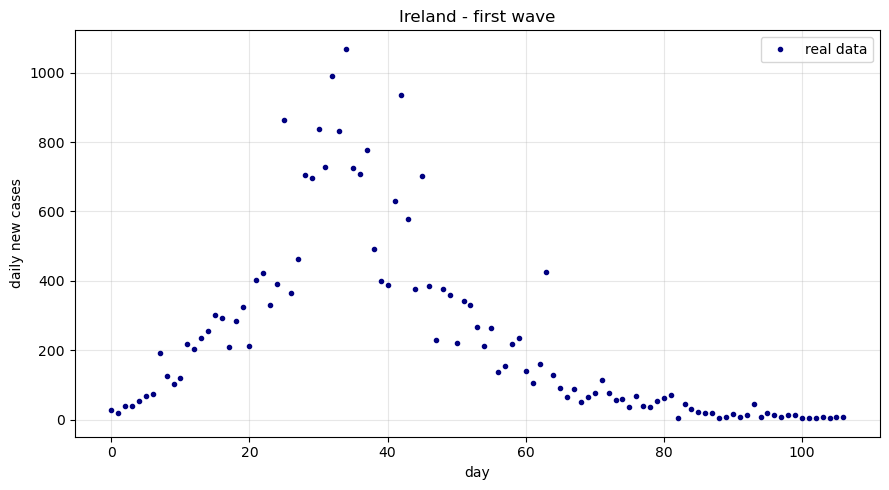

In [3]:
df = pd.read_csv(f"{DATA_DIR}/COVID_19_{COUNTRY}.csv")
df["date"] = pd.to_datetime(df["date"], format="%y/%m/%d")
cases = df["new_cases"].clip(lower=0).to_numpy(dtype=float)
ma7 = pd.Series(cases).rolling(7, min_periods=1).mean().to_numpy()

start = int(np.argmax(cases > 10))
ref = ma7[start:start + 200].max()
search = np.arange(start, len(ma7) - 14)
first_peak = start
for i in search:
    if ma7[i] == ma7[start:i + 15].max() and ma7[i + 1:i + 15].max() < ma7[i] and ma7[i] >= 0.3 * ref:
        first_peak = i
        break
end = len(ma7) - 1
for i in range(first_peak + 1, len(ma7) - 14):
    if ma7[i] == ma7[i - 7:i + 8].min() and ma7[i + 1:i + 15].mean() > ma7[i] * 1.2:
        end = i
        break
else:
    end = first_peak + int(np.argmin(ma7[first_peak:first_peak + 150]))

C_new = cases[start:end + 1]
dates = df["date"].iloc[start:end + 1]
N_eff = float(C_new.sum()) if N_EFF_OVERRIDE is None else float(N_EFF_OVERRIDE)
print(f"{COUNTRY}: days {start}-{end} ({len(C_new)} days), {dates.iloc[0].date()} -> {dates.iloc[-1].date()}, N_eff = {N_eff:,.0f}")

y_obs = C_new / N_eff
ymax = y_obs.max()
sc = 5.0 * ymax

n = len(C_new)
n_train = int(TRAIN_FRAC * n)
t_train = np.arange(n, dtype=float)
T_days = float(n - 1)
print(f"train: days 0-{n_train-1}, test: days {n_train}-{n-1}")

plt.figure(figsize=(9, 5))
plt.plot(t_train, C_new, 'o', ms=3, color='navy', label='real data')
plt.xlabel('day'); plt.ylabel('daily new cases')
plt.title(f'{COUNTRY} - first wave')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
assert alpha < 1, "This notebook is for alpha < 1 only (use the classical notebook for alpha = 1)."   # NEW

S_RANGE = (1.0 / SIGMA_DAYS[1], 1.0 / SIGMA_DAYS[0])
G_RANGE = (1.0 / GAMMA_DAYS[1], 1.0 / GAMMA_DAYS[0])
H = 1.0

def seg_metrics(pred, a, b):
    d = pred[a:b] - C_new[a:b]
    return {"mse": float(np.mean((d / N_eff) ** 2)),
            "rel_l2": float(np.linalg.norm(d) / np.linalg.norm(C_new[a:b])),
            "mae": float(np.mean(np.abs(d)))}

def bound_status(days, lo, hi, tol=0.02):
    span = math.log(hi / lo)
    if math.log(days / lo) < tol * span:
        return "at lower bound"
    if math.log(hi / days) < tol * span:
        return "at upper bound"
    return "interior"

def tail_change(h, k=10):
    h = np.asarray(h, dtype=float); k = min(k, len(h))
    return float(abs(h[-1] - h[-k]) / abs(h[-1])) if k >= 2 else 0.0

def seir_incidence(beta, sigma, gam, E0, I0, a=None, n_fp=40):
    a = alpha if a is None else a
    n_steps = n - 1
    w = np.zeros(n_steps + 1); w[0] = 1.0
    for i in range(1, n_steps + 1):
        w[i] = (1.0 - (a + 1.0) / i) * w[i - 1]
    coef = H ** (-a); g1 = math.gamma(1.0 - a)

    def f(x):
        S, E, I, R = x
        inf = beta * S * I
        return np.array([-inf, inf - sigma * E, sigma * E - gam * I, gam * I])

    x = np.zeros((n_steps + 1, 4)); x[0] = [1.0 - E0 - I0, E0, I0, 0.0]
    for k in range(1, n_steps + 1):
        hist = w[1:k + 1] @ x[k - 1::-1]
        corr = ((k * H) ** (-a) / g1) * x[0]
        xk = x[k - 1].copy()
        for _ in range(n_fp):
            xk = (f(xk) + corr) / coef - hist
        if not np.all(np.isfinite(xk)):
            return np.full(n, np.nan)
        x[k] = xk
    return sigma * x[:, 1] * N_eff

In [5]:
y_data = torch.tensor(y_obs, dtype=torch.float64).unsqueeze(1)
t0 = torch.tensor([[0.0]], dtype=torch.float64)
t_col = torch.tensor(t_train, dtype=torch.float64).unsqueeze(1)
h = (t_col[1] - t_col[0]).item()

def build_GL(N, h, a):
    w = torch.zeros(N, dtype=torch.float64); w[0] = 1.0
    for i in range(1, N):
        w[i] = (1.0 - (a + 1.0) / i) * w[i - 1]
    W = torch.zeros(N, N, dtype=torch.float64)
    for k in range(N):
        W[k, :k + 1] = w[:k + 1].flip(0)
    coef = h ** (-a)
    tt = h * torch.arange(N, dtype=torch.float64)
    c_corr = torch.zeros(N, dtype=torch.float64)
    c_corr[1:] = tt[1:] ** (-a) / math.gamma(1.0 - a)
    return W, coef, c_corr

W_mat, coef_gl, c_corr = build_GL(t_col.shape[0], h, alpha)

def time_derivative(u):
    u = u.double()
    if u.dim() == 2 and u.shape[1] == 1:
        u = u.squeeze(-1)
    D = coef_gl * (W_mat @ u) - c_corr * u[0]
    return torch.cat([torch.zeros(1, dtype=torch.float64), D[1:]]).unsqueeze(1)

In [6]:
def _bounded(raw, lo, hi):
    return lo + (hi - lo) * torch.sigmoid(raw)

def _logit(p):
    p = min(max(p, 0.01), 0.99)
    return math.log(p / (1.0 - p))

class PINN(nn.Module):
    def __init__(self, arch, T, y0_guess, sigma_range, gamma_range, fix_sigma=None,
                 beta0=0.4, sigma0=0.15, gamma0=0.10):
        super().__init__()
        self.T = T
        self.s_lo, self.s_hi = sigma_range
        self.g_lo, self.g_hi = gamma_range
        self.fix_sigma = fix_sigma
        f64 = torch.float64
        self.log_beta = nn.Parameter(torch.tensor([math.log(beta0)], dtype=f64))
        if fix_sigma is None:
            self.raw_sigma = nn.Parameter(torch.tensor(
                [_logit((sigma0 - self.s_lo) / (self.s_hi - self.s_lo))], dtype=f64))
        else:
            self.register_buffer("sigma_const", torch.tensor([fix_sigma], dtype=f64))
        self.raw_gamma = nn.Parameter(torch.tensor(
            [_logit((gamma0 - self.g_lo) / (self.g_hi - self.g_lo))], dtype=f64))
        self.log_E0 = nn.Parameter(torch.tensor([math.log(y0_guess)], dtype=f64))
        self.log_I0 = nn.Parameter(torch.tensor([math.log(y0_guess)], dtype=f64))

        self.net = nn.Sequential()
        self.activation = nn.Tanh()
        self.net.add_module('input', nn.Linear(arch[0], arch[1]))
        self.net.add_module('act1', self.activation)
        for i in range(1, len(arch) - 2):
            self.net.add_module('fc' + str(i), nn.Linear(arch[i], arch[i + 1]))
            self.net.add_module('act' + str(i + 1), self.activation)
        self.net.add_module('output', nn.Linear(arch[-2], arch[-1]))

    def forward(self, x):
        raw = self.net(x / self.T)
        return torch.nn.functional.softplus(raw)

    def phys_params(self):
        ps = [self.log_beta, self.raw_gamma, self.log_E0, self.log_I0]
        if self.fix_sigma is None:
            ps.append(self.raw_sigma)
        return ps

    def params(self):
        sigma = self.sigma_const if self.fix_sigma is not None else _bounded(self.raw_sigma, self.s_lo, self.s_hi)
        gam = _bounded(self.raw_gamma, self.g_lo, self.g_hi)
        return torch.exp(self.log_beta), sigma, gam, torch.exp(self.log_E0), torch.exp(self.log_I0)

loss_fn = nn.MSELoss()

def compute_loss(model):
    beta, sigma, gam, E0, I0 = model.params()

    out = model(t_col)
    S_p = out[:, 0:1]
    E_p = out[:, 1:2] * sc
    I_p = out[:, 2:3] * sc
    R_p = out[:, 3:4]
    out0 = model(t0)

    dt_S = time_derivative(S_p)
    dt_E = time_derivative(E_p)
    dt_I = time_derivative(I_p)
    dt_R = time_derivative(R_p)

    inf = beta * S_p * I_p
    res_S = (dt_S + inf)[1:]
    res_E = (dt_E - (inf - sigma * E_p))[1:]
    res_I = (dt_I - (sigma * E_p - gam * I_p))[1:]
    res_R = (dt_R - gam * I_p)[1:]
    loss_ode = (res_S**2 + res_E**2 + res_I**2 + res_R**2).mean() / (ymax ** 2)

    loss_mass = ((S_p + E_p + I_p + R_p - 1.0) ** 2).mean()
    loss_data = loss_fn(sigma * E_p[:n_train] / ymax, y_data[:n_train] / ymax)
    loss_init = (loss_fn(out0[:, 0:1], (1.0 - E0 - I0).reshape(1, 1))
                 + loss_fn(out0[:, 3:4], torch.zeros_like(out0[:, 3:4]))
                 + loss_fn(out0[:, 1:2] * sc / ymax, E0.reshape(1, 1) / ymax)
                 + loss_fn(out0[:, 2:3] * sc / ymax, I0.reshape(1, 1) / ymax))

    total_loss = W_ODE * loss_ode + W_DATA * loss_data + W_INIT * loss_init + W_MASS * loss_mass
    return total_loss, loss_data

In [7]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def train_one(seed, fix_days=None):
    set_seed(seed)
    t_wall = time.time()
    fix_sigma = None if fix_days is None else 1.0 / fix_days
    model = PINN(ARCH, T_days, y0_guess=10.0 / N_eff, sigma_range=S_RANGE, gamma_range=G_RANGE,
                 fix_sigma=fix_sigma).double()
    phys = model.phys_params()

    hist = {"beta": [], "sigma": [], "gamma": [], "phase": []}
    def log(phase):
        b, s, g, _, _ = model.params()
        hist["beta"].append(b.item()); hist["sigma"].append(s.item()); hist["gamma"].append(g.item())
        hist["phase"].append(phase)

    optim = torch.optim.Adam([{'params': model.net.parameters(), 'lr': 0.001},
                              {'params': phys, 'lr': 0.01}])
    for epoch in range(EPOCHS):
        optim.zero_grad()
        total, _ = compute_loss(model)
        total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optim.step()
        log("adam")

    opt = torch.optim.LBFGS(list(model.net.parameters()) + phys, lr=1.0, max_iter=20, history_size=50,
                            line_search_fn="strong_wolfe", tolerance_grad=1e-12, tolerance_change=1e-14)
    def closure():
        opt.zero_grad()
        loss, _ = compute_loss(model)
        loss.backward()
        return loss

    best_loss = compute_loss(model)[0].item()
    best_state = copy.deepcopy(model.state_dict())
    prev, stall, n_lb = best_loss, 0, 0
    for _ in range(LBFGS_MAX_STEPS):
        try:
            opt.step(closure)
        except RuntimeError:
            break
        cur = compute_loss(model)[0].item()
        if not np.isfinite(cur):
            break
        n_lb += 1
        log("lbfgs")
        if cur < best_loss:
            best_loss, best_state = cur, copy.deepcopy(model.state_dict())
        stall = stall + 1 if abs(prev - cur) <= LBFGS_RTOL * abs(cur) else 0
        prev = cur
        if stall >= 3:
            break
    model.load_state_dict(best_state)

    final_loss = compute_loss(model)[0].item()
    with torch.no_grad():
        out = model(t_col)
        beta, sigma, gam, E0, I0 = [p.item() for p in model.params()]
        inc_pred = (sigma * out[:, 1:2] * sc).squeeze(1).numpy() * N_eff

    tr, te = seg_metrics(inc_pred, 0, n_train), seg_metrics(inc_pred, n_train, n)
    inc_ode = seir_incidence(beta, sigma, gam, E0, I0)
    o_tr, o_te = seg_metrics(inc_ode, 0, n_train), seg_metrics(inc_ode, n_train, n)
    gap = float(np.linalg.norm(inc_pred[n_train:] - inc_ode[n_train:]) / np.linalg.norm(inc_ode[n_train:]))

    lb_slice = slice(EPOCHS, None)
    tc = max(tail_change(hist["beta"][lb_slice]), tail_change(hist["sigma"][lb_slice]), tail_change(hist["gamma"][lb_slice]))
    row = dict(seed=seed, beta=beta, sigma=sigma, inv_sigma=1 / sigma, gamma=gam, inv_gamma=1 / gam, R0=beta / gam,
               E0=E0, I0=I0, E0_cases=E0 * N_eff, I0_cases=I0 * N_eff, loss=final_loss,
               mse=float(np.mean((inc_pred / N_eff - y_obs) ** 2)),
               mse_train=tr["mse"], mse_test=te["mse"], rel_l2_train=tr["rel_l2"], rel_l2_test=te["rel_l2"],
               mae_train=tr["mae"], mae_test=te["mae"], ode_mse_train=o_tr["mse"], ode_mse_test=o_te["mse"],
               pinn_vs_ode_rel_l2_test=gap, lbfgs_steps=n_lb, tail_change=tc,
               sigma_bound="fixed" if fix_days is not None else bound_status(1 / sigma, *SIGMA_DAYS),
               gamma_bound=bound_status(1 / gam, *GAMMA_DAYS), seconds=time.time() - t_wall)
    return {"row": row, "hist": hist, "inc_pred": inc_pred, "inc_ode": inc_ode}

In [8]:
RUNS = {}
for scen, fix_days in SCENARIOS.items():
    print(f"=== {COUNTRY} | scenario '{scen}' | latent period: "
          f"{'estimated' if fix_days is None else str(fix_days) + ' d (fixed)'} ===")
    RUNS[scen] = []
    for sd in SEEDS:
        r = train_one(sd, fix_days)
        RUNS[scen].append(r)
        w = r["row"]
        print(f"seed {sd}: loss {w['loss']:.4e} | beta {w['beta']:.4f} | 1/sigma {w['inv_sigma']:.2f} d ({w['sigma_bound']}) | "
              f"1/gamma {w['inv_gamma']:.2f} d ({w['gamma_bound']}) | R0 {w['R0']:.2f} | "
              f"relL2 train/test {w['rel_l2_train']:.3f}/{w['rel_l2_test']:.3f} | LBFGS {w['lbfgs_steps']} | {w['seconds']:.0f}s")

=== Ireland | scenario 'fixsigma' | latent period: 5.2 d (fixed) ===
seed 0: loss 5.2911e-02 | beta 0.7993 | 1/sigma 5.20 d (fixed) | 1/gamma 3.34 d (interior) | R0 2.67 | relL2 train/test 0.275/0.564 | LBFGS 300 | 33s
seed 1: loss 5.2919e-02 | beta 0.7915 | 1/sigma 5.20 d (fixed) | 1/gamma 3.38 d (interior) | R0 2.67 | relL2 train/test 0.275/0.567 | LBFGS 300 | 31s
seed 2: loss 5.2912e-02 | beta 0.7878 | 1/sigma 5.20 d (fixed) | 1/gamma 3.40 d (interior) | R0 2.68 | relL2 train/test 0.275/0.567 | LBFGS 300 | 31s
seed 3: loss 5.2916e-02 | beta 0.7892 | 1/sigma 5.20 d (fixed) | 1/gamma 3.39 d (interior) | R0 2.68 | relL2 train/test 0.275/0.564 | LBFGS 300 | 36s
seed 4: loss 5.2913e-02 | beta 0.7942 | 1/sigma 5.20 d (fixed) | 1/gamma 3.36 d (interior) | R0 2.67 | relL2 train/test 0.275/0.562 | LBFGS 300 | 44s


In [9]:
QUANT = ["beta", "sigma", "inv_sigma", "gamma", "inv_gamma", "R0", "E0_cases", "I0_cases", "loss",
         "mse_train", "mse_test", "rel_l2_train", "rel_l2_test"]
SEED_TABLE, SUMMARY, BEST = {}, {}, {}
for scen in RUNS:
    tab = pd.DataFrame([r["row"] for r in RUNS[scen]])
    SEED_TABLE[scen] = tab
    SUMMARY[scen] = tab[QUANT].agg(["mean", "std", "min", "max"]).T
    BEST[scen] = min(RUNS[scen], key=lambda r: r["row"]["loss"])
    print(f"\n===== {COUNTRY} | {scen} | best seed (lowest training loss): {BEST[scen]['row']['seed']} =====")
    print(tab[["seed", "beta", "inv_sigma", "inv_gamma", "R0", "loss", "rel_l2_train", "rel_l2_test",
               "sigma_bound", "gamma_bound", "tail_change"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    print(SUMMARY[scen].to_string(float_format=lambda v: f"{v:.4g}"))


===== Ireland | fixsigma | best seed (lowest training loss): 0 =====
 seed   beta  inv_sigma  inv_gamma    R0    loss  rel_l2_train  rel_l2_test sigma_bound gamma_bound  tail_change
    0 0.7993        5.2      3.336 2.666 0.05291        0.2752       0.5636       fixed    interior     0.001156
    1 0.7915        5.2      3.379 2.674 0.05292        0.2752       0.5669       fixed    interior    0.0002431
    2 0.7878        5.2      3.399 2.677 0.05291        0.2752       0.5666       fixed    interior    0.0004597
    3 0.7892        5.2      3.391 2.676 0.05292        0.2752        0.564       fixed    interior    0.0003345
    4 0.7942        5.2      3.363 2.671 0.05291        0.2752       0.5617       fixed    interior     0.001609
                  mean       std       min       max
beta            0.7924  0.004563    0.7878    0.7993
sigma           0.1923         0    0.1923    0.1923
inv_sigma          5.2         0       5.2       5.2
gamma           0.2964  0.002206    0.29

[fixsigma] best seed 0: MSE train = 1.845e-05 | MSE test = 1.130e-07


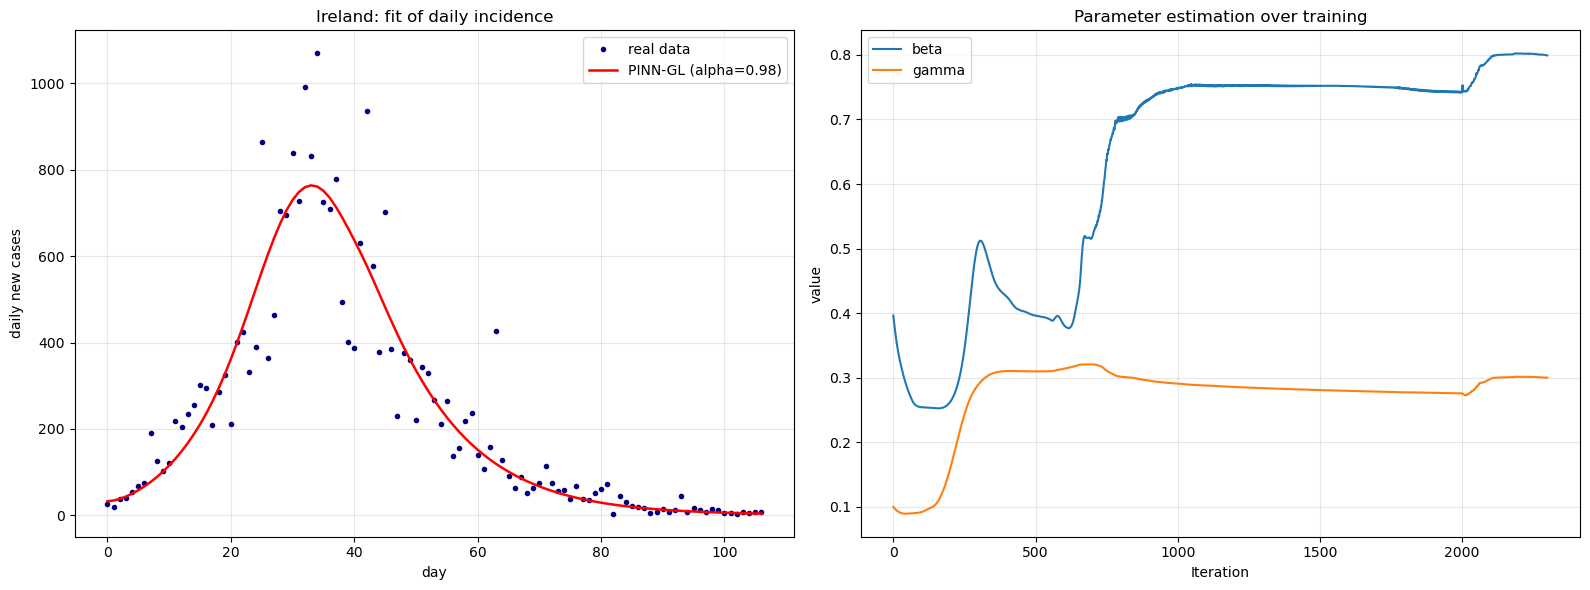

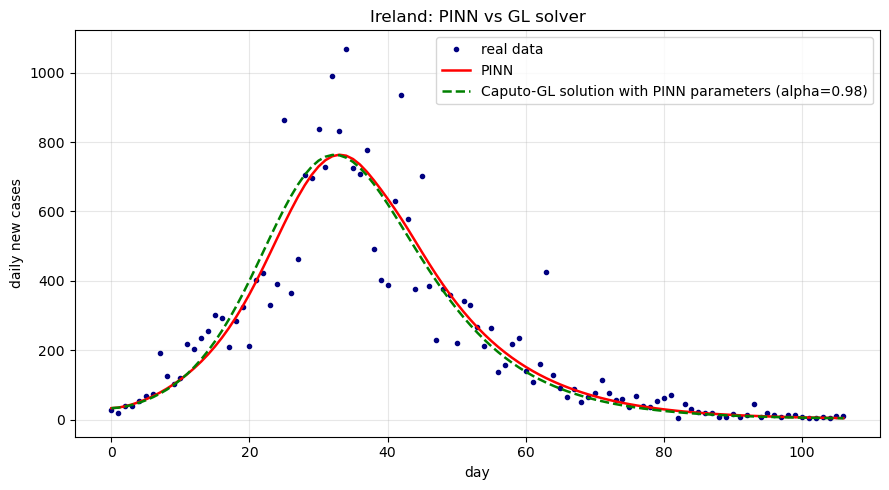

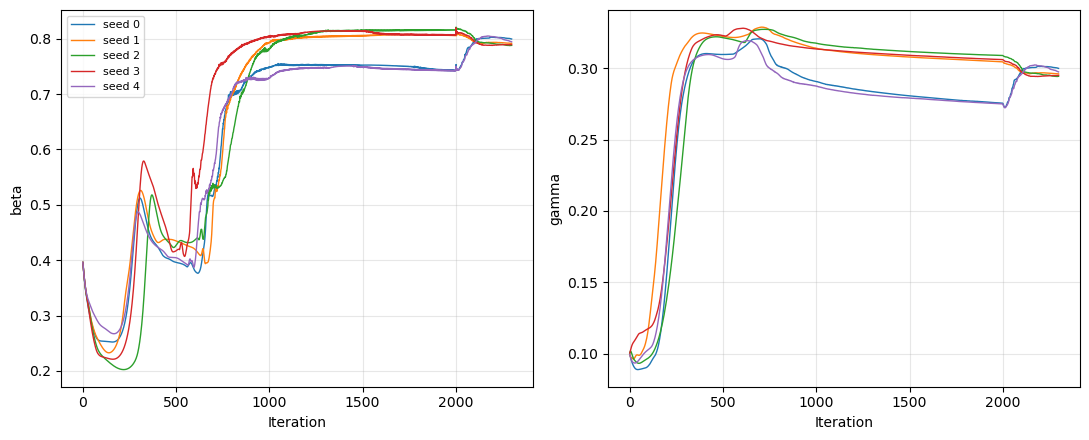

In [10]:
def save_axes(fig, names, suffix):
    fig.canvas.draw()
    for ax, name in zip(fig.axes, names):
        ext = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
        fig.savefig(f"{name}_{suffix}.pdf", bbox_inches=ext.expanded(1.02, 1.02))

for scen in RUNS:
    suffix = f"{COUNTRY}_{TAG}_{scen}"
    best = BEST[scen]; w = best["row"]; hs = best["hist"]
    print(f"[{scen}] best seed {w['seed']}: MSE train = {w['mse_train']:.3e} | MSE test = {w['mse_test']:.3e}")

    fig = plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    plt.plot(t_train, C_new, 'o', ms=3, color='navy', label='real data')
    plt.plot(t_train, best["inc_pred"], 'r-', lw=1.8, label=f'PINN-GL (alpha={alpha})')
    plt.xlabel('day'); plt.ylabel('daily new cases'); plt.title(f'{COUNTRY}: fit of daily incidence')
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.subplot(1, 2, 2)
    it = np.arange(len(hs["beta"]))
    plt.plot(it, hs["beta"], label='beta'); plt.plot(it, hs["gamma"], label='gamma')
    if SCENARIOS[scen] is None:
        plt.plot(it, hs["sigma"], label='sigma')
    plt.xlabel('Iteration'); plt.ylabel('value'); plt.title('Parameter estimation over training')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    save_axes(fig, ["fit", "params"], suffix); plt.show()

    plt.figure(figsize=(9, 5))
    plt.plot(t_train, C_new, 'o', ms=3, color='navy', label='real data')
    plt.plot(t_train, best["inc_pred"], 'r-', lw=1.8, label='PINN')
    plt.plot(t_train, best["inc_ode"], 'g--', lw=1.8, label=f'Caputo-GL solution with PINN parameters (alpha={alpha})')
    plt.xlabel('day'); plt.ylabel('daily new cases'); plt.title(f'{COUNTRY}: PINN vs GL solver')
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig(f"solver_{suffix}.pdf", bbox_inches="tight"); plt.show()

    keys = [("beta", "beta"), ("gamma", "gamma")]
    if SCENARIOS[scen] is None:
        keys.append(("sigma", "sigma"))
    fig = plt.figure(figsize=(5.5 * len(keys), 4.5))
    for k, (key, lab) in enumerate(keys):
        plt.subplot(1, len(keys), k + 1)
        for r in RUNS[scen]:
            plt.plot(r["hist"][key], lw=1, label=f"seed {r['row']['seed']}")
        plt.xlabel('Iteration'); plt.ylabel(lab); plt.grid(alpha=0.3)
        if k == 0: plt.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"seeds_{suffix}.pdf", bbox_inches="tight"); plt.show()

In [11]:
SCEN = "fixsigma"                                                   # NEW
best = BEST[SCEN]
inc_pred, inc_ode = best["inc_pred"], best["inc_ode"]
beta, sigma, gam = best["row"]["beta"], best["row"]["sigma"], best["row"]["gamma"]
E0, I0 = best["row"]["E0"], best["row"]["I0"]

expected_sigma = 1.0 / SCENARIOS[SCEN]
assert np.isclose(sigma, expected_sigma), f"Sigma mismatch: expected {expected_sigma}, got {sigma}"

def mse_range(pred, a, b):
    return np.mean((pred[a:b] / N_eff - y_obs[a:b]) ** 2)

print(f"Best seed: {best['row']['seed']}")
print(f"beta = {beta:.4f} | sigma = {sigma:.6f} | gamma = {gam:.4f}")
print(f"1/sigma = {1/sigma:.2f} days | 1/gamma = {1/gam:.2f} days")
print(f"{'':14s}{'train':>12s}{'test':>12s}")
print(f"{'PINN':14s}{mse_range(inc_pred, 0, n_train):12.3e}{mse_range(inc_pred, n_train, n):12.3e}")
print(f"{'GL step solver':14s}{mse_range(inc_ode, 0, n_train):12.3e}{mse_range(inc_ode, n_train, n):12.3e}")

err = (inc_pred - inc_ode) / N_eff
diag = pd.DataFrame(list({
    "sigma fixed (1/day)": sigma,
    "latent period (days)": 1.0 / sigma,
    "1/sigma bound status": best["row"]["sigma_bound"],
    "1/gamma bound status": best["row"]["gamma_bound"],
    "best seed": best["row"]["seed"],
    "final total loss": best["row"]["loss"],
    "MSE solver train": mse_range(inc_ode, 0, n_train),
    "MSE solver test": mse_range(inc_ode, n_train, n),
    "MSE PINN-vs-solver train": np.mean(err[:n_train] ** 2),
    "MSE PINN-vs-solver test": np.mean(err[n_train:] ** 2),
    "rel. L2 PINN-vs-solver test": (np.linalg.norm(inc_pred[n_train:] - inc_ode[n_train:])
                                    / np.linalg.norm(inc_ode[n_train:])),
    "lbfgs_steps": best["row"]["lbfgs_steps"],
    "tail_change": best["row"]["tail_change"],
    "seconds": best["row"]["seconds"],
}.items()), columns=["Quantity", "Value"])

idx_all = np.arange(len(cases))
full_series = pd.DataFrame({
    "day": idx_all, "date": df["date"], "new_cases": cases, "ma7": ma7,
    "in_wave": (idx_all >= start) & (idx_all <= end),
})

fname = f"results_{COUNTRY}_alpha_{alpha}_{SCEN}.xlsx"              # NEW
with pd.ExcelWriter(fname) as writer:
    pd.DataFrame({
        "Parameter": ["country", "alpha", "N_eff", "wave_start_day", "wave_end_day", "days",
                      "beta", "sigma (fixed, 1/day)", "latent period (days)", "gamma", "1/gamma (days)",
                      "beta/gamma", "E0 (cases)", "I0 (cases)", "MSE", "MSE train", "MSE test",
                      "sigma bound status", "gamma bound status"],
        "Value": [COUNTRY, alpha, N_eff, start, end, len(C_new),
                  beta, sigma, 1.0 / sigma, gam, 1.0 / gam,
                  beta / gam, E0 * N_eff, I0 * N_eff,
                  best["row"]["mse"], best["row"]["mse_train"], best["row"]["mse_test"],
                  best["row"]["sigma_bound"], best["row"]["gamma_bound"]],
    }).to_excel(writer, sheet_name="parameters", index=False)

    pd.DataFrame({"day": t_train, "date": dates.values, "real_cases": C_new,
                  "model_cases": inc_pred}).to_excel(writer, sheet_name="fit", index=False)

    hist = best["hist"]
    pd.DataFrame({"iteration": range(len(hist["beta"])), "beta": hist["beta"],
                  "sigma": [sigma] * len(hist["beta"]), "gamma": hist["gamma"],
                  "phase": hist["phase"]}).to_excel(writer, sheet_name="history", index=False)

    diag.to_excel(writer, sheet_name="diagnostics", index=False)
    full_series.to_excel(writer, sheet_name="full_series", index=False)
    pd.DataFrame({"day": t_train, "solver_cases": inc_ode}).to_excel(writer, sheet_name="solver", index=False)
    SEED_TABLE[SCEN].to_excel(writer, sheet_name="seeds", index=False)
    SUMMARY[SCEN].to_excel(writer, sheet_name="summary")

print(f"Saved: {fname}")

Best seed: 0
beta = 0.7993 | sigma = 0.192308 | gamma = 0.2998
1/sigma = 5.20 days | 1/gamma = 3.34 days
                     train        test
PINN             1.845e-05   1.130e-07
GL step solver   1.965e-05   1.249e-07
Saved: results_Ireland_alpha_0.98_fixsigma.xlsx
